In [1]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# 2. Load dataset
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name='Species')

print("First 5 rows of features:")
display(X.head())
print("\nTarget values:")
display(y.head())


First 5 rows of features:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target values:


0    0
1    0
2    0
3    0
4    0
Name: Species, dtype: int64

In [3]:
# 3. Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"\nTraining set size: {X_train.shape}, Testing set size: {X_test.shape}")



Training set size: (120, 4), Testing set size: (30, 4)


In [4]:
# 4. Initialize and train Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [5]:
# 5. Make predictions
y_pred_train = dt_model.predict(X_train)
y_pred_test = dt_model.predict(X_test)


In [6]:
# 6. Evaluation
print("\n=== Training Accuracy ===")
print(accuracy_score(y_train, y_pred_train))
print("\n=== Testing Accuracy ===")
print(accuracy_score(y_test, y_pred_test))

print("\n=== Confusion Matrix (Test Set) ===")
print(confusion_matrix(y_test, y_pred_test))

print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred_test, target_names=iris.target_names))



=== Training Accuracy ===
1.0

=== Testing Accuracy ===
1.0

=== Confusion Matrix (Test Set) ===
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



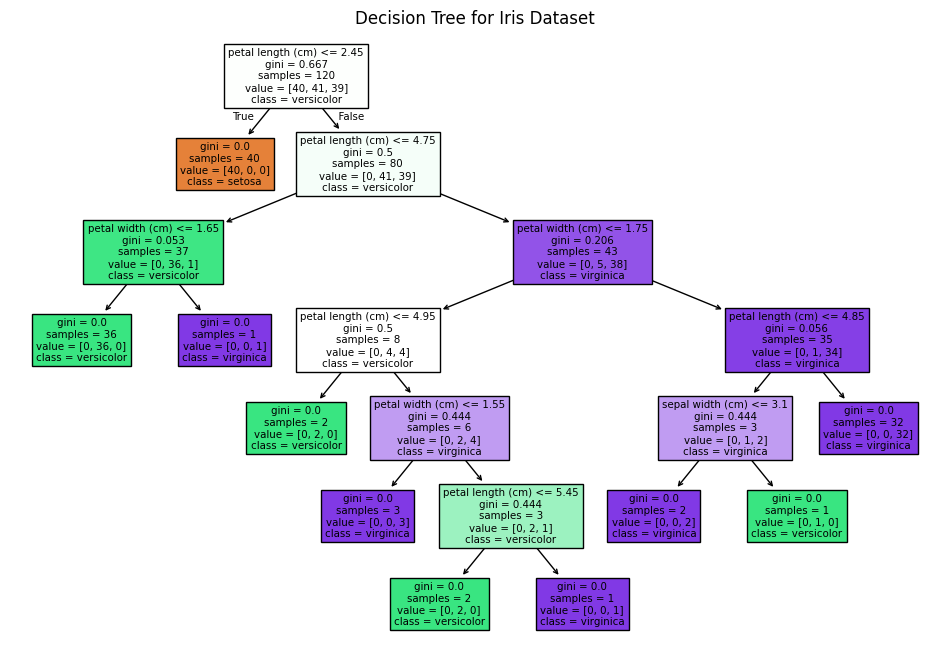

In [7]:
# 7. Plot Decision Tree
plt.figure(figsize=(12,8))
plot_tree(dt_model, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.title("Decision Tree for Iris Dataset")
plt.show()
